# Repo type, owner and name distributions

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd

discussion_paths = "data/discussion_full_data.xlsx"
repo_card_path = "data/cards_full_data.xlsx"
commit_path = "data/commits_full_data.xlsx"

sheet = "Final_Labels"  
discussion_paths = pd.read_excel(discussion_paths, sheet_name=sheet)
repo_card = pd.read_excel(repo_card_path, sheet_name=sheet)
commits = pd.read_excel(commit_path, sheet_name=sheet)
print(f"commits shape {commits.shape}")
print(f"discussion shape {discussion_paths.shape}") 
print(f"repo card shape {repo_card.shape}")
      


# Useful_repo_id looks like "<type>/<owner>/<name>"
def split_repo_id(df):
    parts = df["Useful_repo_id"].str.split("/", n=2, expand=True)
    df["repo_type"] = parts[0]
    df["owner"] = parts[1]
    df["name"] = parts[2]
    return df

# ---------------------------------------------------------- Discussions
discussion_paths = split_repo_id(discussion_paths)
discussion_paths.to_excel("data/new_discussion_analysis.xlsx", index=False)
final_discussions = pd.read_excel("data/new_discussion_analysis.xlsx")

# # ---------------------------------------------------------- Repo cards
repo_card = split_repo_id(repo_card)
repo_card.to_excel("data/new_repo_card_analysis.xlsx", index=False)
final_repo_card = pd.read_excel("data/new_repo_card_analysis.xlsx")

# ---------------------------------------------------------- Commits
commits = split_repo_id(commits)
commits.to_excel("data/new_commits_analysis.xlsx", index=False)
final_commits = pd.read_excel("data/new_commits_analysis.xlsx")

# ---------------------------------------------------------- Discussions
final_discussions["Label"] = final_discussions["Label"].str.lower()
final_discussions_tp = final_discussions[final_discussions["Label"].str.strip() != "false positives"].copy()
print(f"{len(final_discussions_tp)} discussions, {final_discussions_tp['discussion_url'].nunique()} unique discussions after removing false positives")
final_discussions_tp_en = final_discussions_tp[final_discussions_tp["Language"].isna() ].copy()
print(f"{len(final_discussions_tp_en)} discussions, {final_discussions_tp_en['discussion_url'].nunique()} unique discussions after removing other language")

# get just false positives
final_discussions_fp = final_discussions[final_discussions["Label"].str.strip() == "false positives"].copy()

# ---------------------------------------------------------- Repo cards
final_repo_card["Label"] = final_repo_card["Label"].str.lower()
final_repo_card_tp = final_repo_card[final_repo_card["Label"].str.strip() != "false positives"].copy()
print(f"{len(final_repo_card_tp)} repo cards, {final_repo_card_tp['card_url'].nunique()} unique repos after removing false positives")
final_repo_card_tp_en = final_repo_card_tp[final_repo_card_tp["Language"].isna() ].copy()
print(f"{len(final_repo_card_tp_en)} commits, {final_repo_card_tp_en['card_url'].nunique()} unique repo ards after removing other language")

# get just false positives
final_repo_card_fp = final_repo_card[final_repo_card["Label"].str.strip() == "false positives"].copy()

# ---------------------------------------------------------- Commits
final_commits["Label"] = final_commits["Label"].str.lower()
final_commits_tp = final_commits[final_commits["Label"].str.strip() != "false positives"].copy()
print(f"{len(final_commits_tp)} commits, {final_commits_tp['commit_url'].nunique()} unique commits after removing false positives")
final_commits_tp_en = final_commits_tp[final_commits_tp["Language"].isna() ].copy()
print(f"{len(final_commits_tp_en)} commits, {final_commits_tp_en['commit_url'].nunique()} unique commits after removing other language")

# get just false positives
final_commits_fp = final_commits[final_commits["Label"].str.strip() == "false positives"].copy()

commits shape (1259, 8)
discussion shape (73, 10)
repo card shape (2000, 6)
41 discussions, 41 unique discussions after removing false positives
41 discussions, 41 unique discussions after removing other language
1394 repo cards, 1394 unique repos after removing false positives
1394 commits, 1394 unique repo ards after removing other language
132 commits, 132 unique commits after removing false positives
132 commits, 132 unique commits after removing other language


### FInal positives

In [2]:
final_discussions_fp

,Useful_repo_id,Useful_discussion_num,ids,orphan,no_kids,discussion_url,type,sources,Label,Language,repo_type,owner,name
0,datasets/Avdhootx7/eu-ai-act-nlp-dataset,1,['6a6fdcbf21709a3fec1a9f8f'],True,False,https://huggingface.co/datasets/Avdhootx7/eu-a...,datasets,AI Act,false positives,NaN,datasets,Avdhootx7,eu-ai-act-nlp-dataset
2,datasets/ComplianceDataLab/eu-ai-act-complianc...,1,['69cb13eb89b140d08fa6d791'],True,False,https://huggingface.co/datasets/ComplianceData...,datasets,AI Act,false positives,NaN,datasets,ComplianceDataLab,eu-ai-act-compliance-scenarios
3,datasets/NMAIResearch/eu-ai-act-article-50-sco...,1,['6a82519161b44a6372a3b85b'],True,False,https://huggingface.co/datasets/NMAIResearch/e...,datasets,AI Act,false positives,NaN,datasets,NMAIResearch,eu-ai-act-article-50-scoreboard
4,datasets/RedStar-Reasoning/multimodal_dataset,2,['6806f68a1cb76d8c7f4e3f9d'],True,False,https://huggingface.co/datasets/RedStar-Reason...,datasets,AI Act,false positives,NaN,datasets,RedStar-Reasoning,multimodal_dataset
5,datasets/SkillSprinters/eu-ai-act-annex-iii-kl...,1,['6a20c285946e2b18ae05c588'],True,False,https://huggingface.co/datasets/SkillSprinters...,datasets,AI Act,false positives,NaN,datasets,SkillSprinters,eu-ai-act-annex-iii-klassifikation-de
6,datasets/TurboQuantArchitect/eu-ai-act-reasoni...,1,['69d9919dc586bffa685a44f7'],True,False,https://huggingface.co/datasets/TurboQuantArch...,datasets,AI Act,false positives,NaN,datasets,TurboQuantArchitect,eu-ai-act-reasoning-sample
9,datasets/dam9/eu-ai-act-red-teaming-v1,1,['69716b32afc40c86d2040411'],True,False,https://huggingface.co/datasets/dam9/eu-ai-act...,datasets,AI Act,false positives,NaN,datasets,dam9,eu-ai-act-red-teaming-v1
10,datasets/danielnoumon/eu-ai-act-nl-queries,1,['69ae10096cd84ef6ec104ae7'],True,False,https://huggingface.co/datasets/danielnoumon/e...,datasets,AI Act,false positives,NaN,datasets,danielnoumon,eu-ai-act-nl-queries
13,datasets/hugoramallo/legal-ai-act-spanish-sft-7k,1,['69d991c0fe8a470aa17ef7c1'],True,False,https://huggingface.co/datasets/hugoramallo/le...,datasets,AI Act,false positives,NaN,datasets,hugoramallo,legal-ai-act-spanish-sft-7k
16,datasets/jeroenherczeg/eu-ai-act,1,['6a02701725a6d3ed56f05c81'],True,False,https://huggingface.co/datasets/jeroenherczeg/...,datasets,AI Act,false positives,NaN,datasets,jeroenherczeg,eu-ai-act


In [3]:
final_discussions_fp["has_AIA"] = final_discussions_fp["sources"].str.contains("AIA", na=False)
final_discussions_fp["just_AIA"] = final_discussions_fp["sources"] == "AIA"

final_repo_card_fp["has_AIA"] = final_repo_card_fp["sources"].str.contains("AIA", na=False)
final_repo_card_fp["just_AIA"] = final_repo_card_fp["sources"] == "AIA"

final_commits_fp["has_AIA"] = final_commits_fp["sources"].str.contains("AIA", na=False)
final_commits_fp["just_AIA"] = final_commits_fp["sources"] == "AIA"

In [4]:
sum(final_discussions_fp["has_AIA"]) + sum(final_repo_card_fp["has_AIA"]) + sum(final_commits_fp["has_AIA"])

1400

In [5]:
sum(final_discussions_fp["just_AIA"]) + sum(final_repo_card_fp["just_AIA"]) + sum(final_commits_fp["just_AIA"])

1399

## COUNTS

In [6]:
label_map = {
    "regulated":           "Compliance and responsibility",
    "regulated*":            "Non applicability claims",
    "false positive":       "false positive",
    "artifact":             "Compliance artifacts",
    "understanding":        "Knowledge resources",
    "regulated/violation": "Reported alleged violations",
}

# # Normalize whitespace and case so " Regulated " still matches
normalized = final_commits_tp_en["Label"].astype(str).str.strip().str.lower()
final_commits_tp_en["Label_tag"] = final_commits_tp_en["Label"]
final_commits_tp_en["Label"] = normalized.map(label_map)
unmatched_commits = final_commits_tp_en.loc[final_commits_tp_en["Label"].isna() & final_commits_tp_en["Label_tag"].notna(), "Label_tag"].unique()

normalized = final_repo_card_tp_en["Label"].astype(str).str.strip().str.lower()
final_repo_card_tp_en["Label_tag"] = final_repo_card_tp_en["Label"]
final_repo_card_tp_en["Label"] = normalized.map(label_map)
unmatched_cards = final_repo_card_tp_en.loc[final_repo_card_tp_en["Label"].isna() & final_repo_card_tp_en["Label_tag"].notna(), "Label_tag"].unique()

normalized = final_discussions_tp_en["Label"].astype(str).str.strip().str.lower()
final_discussions_tp_en["Label_tag"] = final_discussions_tp_en["Label"]
final_discussions_tp_en["Label"] = normalized.map(label_map)
unmatched_disc = final_discussions_tp_en.loc[final_discussions_tp_en["Label"].isna() & final_discussions_tp_en["Label_tag"].notna(), "Label_tag"].unique()

In [ ]:
final_commits_tp_en.Label.value_counts()

In [ ]:
final_repo_card_tp_en.Label.value_counts()

In [ ]:
final_discussions_tp_en.Label.value_counts()

## In general data plots

In [331]:
TYPE_REPO = ["models", "datasets", "spaces"]
TYPE_COLORS = {"models": "#327bf0", "datasets": "#e08a1e", "spaces": "#1f9d8a"}  # fixed colour per repo type
NEUTRAL = "#FF9D00"

sns.set_theme(style="whitegrid", context="notebook")
sns.set_style("whitegrid", {"axes.spines.top": False, "axes.spines.right": False, "grid.color": "#e3e7ec"})

In [281]:
# Counts  per repo types 
def hbar(ax, column, data, color, title, order=None, xlabel="Number of Discussions", unique_by=None):
    """Horizontal seaborn bar chart of value counts, largest on top, count at the bar end."""
    if unique_by is not None:
        data = data.drop_duplicates(subset=[column, unique_by])
        
    if order is None:
        order = data[column].value_counts().index  # largest on top
    sns.countplot(data=data, y=column, order=order, color=color, width=0.7, ax=ax)
    for container in ax.containers:
        ax.bar_label(container, padding=3, fontsize=10)
    ax.set_xlim(0, ax.get_xlim()[1] + 0.5)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")
    ax.grid(axis="y", visible=False)
    ax.set_title(title, loc="left")

### Discussions

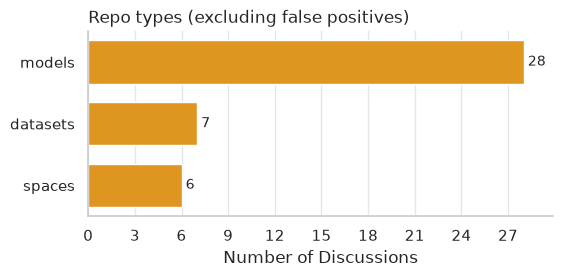

In [309]:
# Counts  per repo types 
fig, ax = plt.subplots(figsize=(6, 2.4))
hbar(ax, "repo_type", final_discussions_tp_en, NEUTRAL, "Repo types (excluding false positives)", TYPE_REPO, xlabel="Number of Discussions")

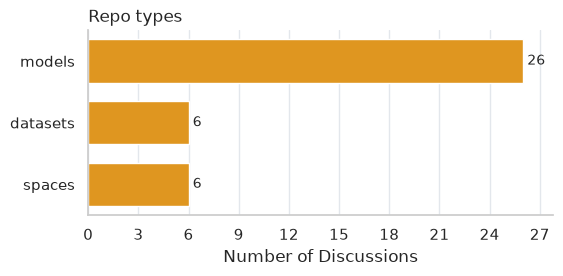

In [283]:
# Counts  per repo types 
fig, ax = plt.subplots(figsize=(6, 2.4))
hbar(ax, "repo_type", final_discussions_tp_en, NEUTRAL, "Repo types", TYPE_REPO, xlabel="Number of Discussions", unique_by="Useful_repo_id")


### Repo cards

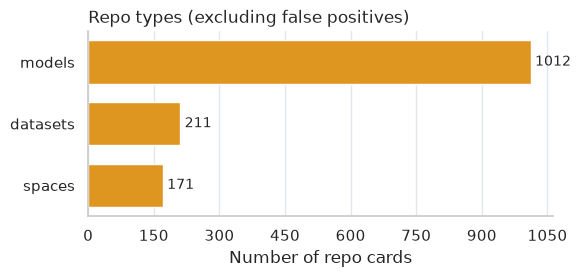

In [284]:
# Counts  per repo types  RE cards
fig, ax = plt.subplots(figsize=(6, 2.4))
hbar(ax, "repo_type", final_repo_card_tp_en, NEUTRAL, "Repo types (excluding false positives)", TYPE_REPO, xlabel="Number of repo cards")

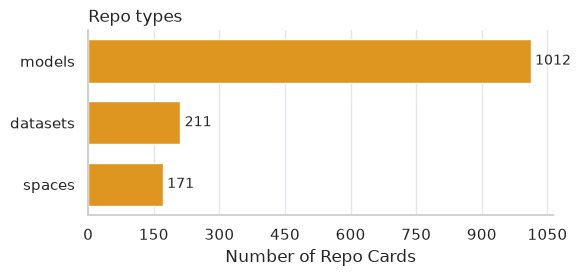

In [285]:
# Counts  per repo types  RE cards
fig, ax = plt.subplots(figsize=(6, 2.4))
hbar(ax, "repo_type", final_repo_card_tp_en, NEUTRAL, "Repo types", TYPE_REPO, xlabel="Number of Repo Cards", unique_by="Useful_repo_id")


### COMMITS

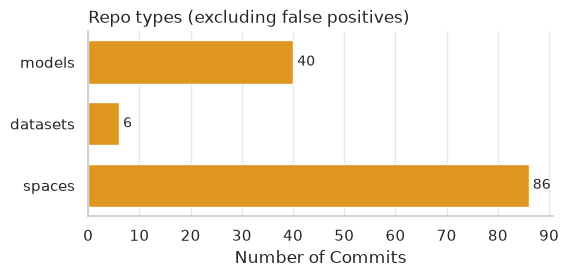

In [286]:
# Counts  per repo types # of discussions
fig, ax = plt.subplots(figsize=(6, 2.4))
hbar(ax, "repo_type", final_commits_tp_en, NEUTRAL, "Repo types (excluding false positives)", TYPE_REPO, xlabel="Number of Commits")


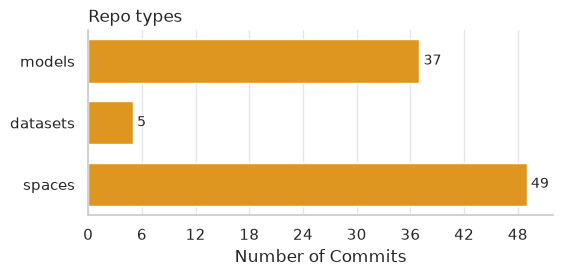

In [287]:
# Counts  on how many unique discussions have at least one discussion 
fig, ax = plt.subplots(figsize=(6, 2.4))
hbar(ax, "repo_type", final_commits_tp_en, NEUTRAL, "Repo types", TYPE_REPO, xlabel="Number of Commits", unique_by="Useful_repo_id")

## Divided by repo type

In [ ]:
import numpy as np
import matplotlib
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42
import matplotlib.pyplot as plt
import pandas as pd

# Okabe–Ito palette: colorblind-safe and prints well
LABEL_COLORS = {
    "Compliance and responsibility": "#0072B2",  # blue
    "Non applicability claims":      "#56B4E9",  # light blue (also from "regulated")
    "Reported alleged violations": "#D55E00",  # red-orange (stands out)
    "Compliance artifacts":          "#009E73",  # green
    "Knowledge resources":           "#E69F00",  # orange
    "false positive":                "#999999",  # grey (not a real category)
}

def fmt_pct(p):
    """Show 10 instead of 10.00, but keep 33.33 as is."""
    if abs(p - round(p)) < 1e-9:
        return f"{round(p)}%"
    return f"{p:.2f}%"


def stacked_share(data, group, column, group_order=None, hue_order=None, colors=None,
                  name="commits", unique_by=None, min_label=10, callouts=True,
                  show_axis=True, totals="axis", legend_ncol=None,
                  title=None, subtitle=None, figsize=None, bar_width=None, save=None):
    # ---------- Counting ----------
    if unique_by is not None:
        totals_n = data.groupby(group)[unique_by].nunique()
        data = data.drop_duplicates(subset=[group, column, unique_by])
        name = "repositories"

    counts = pd.crosstab(data[group], data[column])

    rows = list(group_order) if group_order else list(counts.sum(axis=1).sort_values(ascending=False).index)
    cols = list(hue_order) if hue_order else list(counts.sum().sort_values(ascending=False).index)

    # Never drop data silently
    missing = [c for c in counts.columns if c not in cols]
    if missing:
        print(f"Warning: labels not in hue_order were added: {missing}")
        cols += missing
    absent = [c for c in cols if c not in counts.columns]
    if absent:
        print(f"Note: labels in hue_order with no data: {absent}")

    counts = counts.reindex(index=rows, columns=cols, fill_value=0)
    share = counts.div(counts.sum(axis=1), axis=0) * 100

    if unique_by is None:
        totals_n = counts.sum(axis=1)
    totals_n = totals_n.reindex(rows)

    # ---------- Automatic sizing ----------
    has_callouts = callouts and ((share < min_label) & (counts > 0)).any().any()

    if bar_width is None:
        bar_width = 0.5 if has_callouts else 0.65
    if figsize is None:
        height = (1.0 if has_callouts else 0.7) * len(rows) + 0.9
        figsize = (10, height)

    # ---------- Bars ----------
    colors = colors or {}
    ax = share.plot.barh(stacked=True, color=[colors.get(c) for c in cols],
                         width=bar_width, figsize=figsize, legend=False)
    ax.grid(False)          # must come after plotting
    fig = ax.figure
    ax.invert_yaxis()       # first group on top

    # ---------- Segment labels ----------
    small = {}  
    for col, container in zip(cols, ax.containers):
        inside = []
        for i, (rect, p, k) in enumerate(zip(container.patches, share[col], counts[col])):
            if p >= min_label:
                # inside.append(f"{p:.0f}% ({k})")
                # inside.append(f"{p:.2f}% ({k})")
                inside.append(f"{fmt_pct(p)} ({k})")
            else:
                inside.append("")
                if k > 0:
                    x_center = rect.get_x() + rect.get_width() / 2
                    small.setdefault(i, []).append(
                        # (x_center, f"{p:.1f}% ({k})", colors.get(col, "#333333")))
                        # (x_center, f"{p:.2f}% ({k})", colors.get(col, "#333333")))
                        (x_center, f"{fmt_pct(p)} ({k})", colors.get(col, "#333333")))
                        
        ax.bar_label(container, labels=inside, label_type="center",
                     color="white", fontsize=10, fontweight="bold")

    # ---------- Callouts for small segments ----------
    if has_callouts:
        for i, items in small.items():
            n_items = len(items)
            for j, (xc, text, col) in enumerate(items):
                y_text = i + (j - (n_items - 1) / 2) * 0.24   # spread labels vertically
                ax.annotate(text, xy=(xc, i), xytext=(104, y_text),
                            va="center", ha="left", fontsize=9, fontweight="bold", color=col,
                            arrowprops=dict(arrowstyle="-", color=col, lw=0.9,
                                            shrinkA=2, shrinkB=0),
                            annotation_clip=False)
                ax.plot(xc, i, "o", ms=3, color=col, zorder=5, clip_on=False)

    # ---------- Totals per group ----------
    if totals == "axis":
        ax.set_yticks(range(len(rows)), [f"{r}\n($n$ = {totals_n[r]})" for r in rows])
    elif totals == "end" and not has_callouts:
        for i, r in enumerate(rows):
            ax.text(101, i, f"$n$ = {totals_n[r]}", va="center",
                    fontsize=10, color="#555555")

    # ---------- Legend ----------
    ncol = legend_ncol or min(len(cols), 3)
    ax.legend(ncol=ncol, loc="lower left", bbox_to_anchor=(0, 1.02),
              frameon=False, fontsize=10, handlelength=1, handleheight=1)

    # ---------- Axes ----------
    if has_callouts:
        ax.set_xlim(0, 125)
    elif totals == "end":
        ax.set_xlim(0, 112)
    else:
        ax.set_xlim(0, 100)

    ax.set_ylabel("")
    ax.tick_params(axis="y", length=0, labelsize=11)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)

    if show_axis:
        ax.set_xticks([0, 25, 50, 75, 100])
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
        ax.spines["bottom"].set_bounds(0, 100)
        # ax.set_xlabel(f"Share of {name}")
        ax.set_xlabel(f"Share of {name} ($n$ = {int(totals_n.sum()):,})")
    else:
        ax.set_xticks([])
        ax.set_xlabel("")
        ax.spines["bottom"].set_visible(False)

    # ---------- Title and subtitle ----------
    top = 1.0
    if title:
        fig.text(0.01, 0.99, title, fontsize=13, fontweight="bold", va="top")
        top -= 0.12
    if subtitle:
        fig.text(0.01, 0.99 if not title else 0.88, subtitle,
                 fontsize=10.5, color="#555555", va="top")
        top -= 0.08

    plt.tight_layout(rect=[0, 0, 1, top])
    if save:
        fig.savefig(save, bbox_inches="tight")
    plt.show()
    return counts, share

### Discussions

In [ ]:
final_discussions_tp_en["Label"].value_counts()

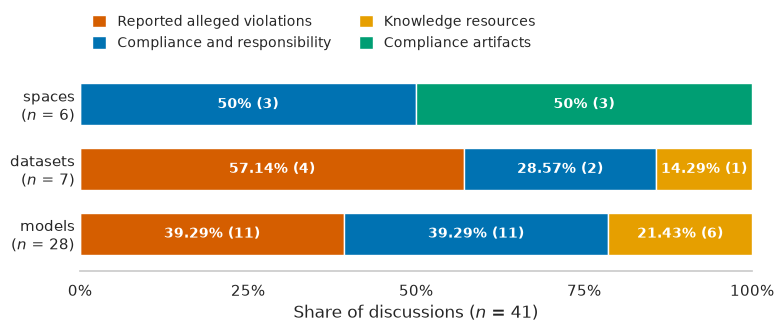

In [360]:
counts_c, share_c = stacked_share(
    final_discussions_tp_en, "repo_type", "Label",
    group_order=["spaces", "datasets", "models"], name="discussions",
    hue_order=["Reported alleged violations", "Compliance and responsibility", "Knowledge resources", "Compliance artifacts"],
    colors=LABEL_COLORS,
    save="discussions_share_by_type.pdf", figsize=(8, 3.5), legend_ncol=2,)

### Repo cards

In [ ]:
final_repo_card_tp_en["Label"].value_counts()

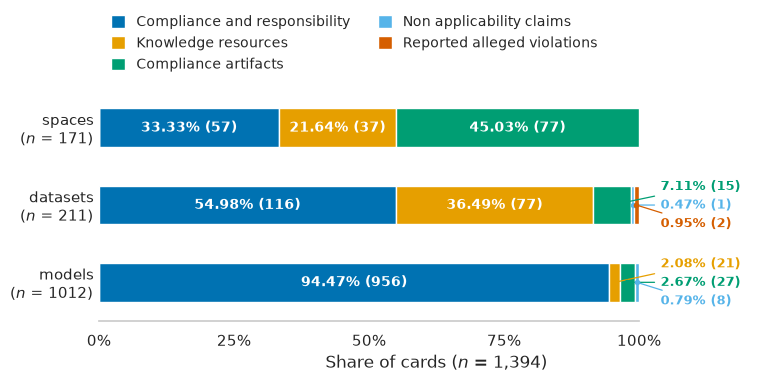

In [363]:
counts_r, share_r = stacked_share(
    final_repo_card_tp_en, "repo_type", "Label",
    group_order=["spaces", "datasets", "models"], name="cards",
    hue_order=["Compliance and responsibility", "Knowledge resources",
               "Compliance artifacts", "Non applicability claims",
               "Reported alleged violations"],
    colors=LABEL_COLORS,
    save="cards_share_by_type.pdf", 
     figsize=(8, 4), legend_ncol=2,)

### COMMITS

In [ ]:
final_commits_tp_en["Label"].value_counts()

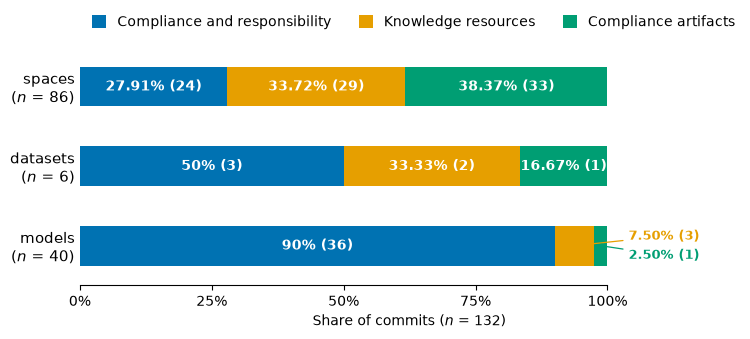

In [11]:
counts_c, share_c = stacked_share(
    final_commits_tp_en, "repo_type", "Label",
    group_order=["spaces", "datasets", "models"], name="commits",
    hue_order=["Compliance and responsibility", "Knowledge resources", "Compliance artifacts"],
    colors=LABEL_COLORS,
    save="commits_share_by_type.pdf", 
    figsize=(8, 3.5),)